# Week 47, Monday lecture: boosting — AdaBoost, steepest descent in function space, gradient boosting and XGBoost

**FYS-STK3155/4155, Monday November 16, 2026**

This notebook contains the code behind every figure and number in the Monday
slides (`week47slides.pdf`), following Chapter 7, Sections 7.11–7.16 (and the
boosting material of the DocOnce notes). It runs in about a minute and needs
NumPy, Matplotlib, scikit-learn and `xgboost` (`pip install xgboost`).

*Part 0* — last week's CART tree with **sample weights**: the only change a
weak learner needs for AdaBoost.

*Part 1* — **AdaBoost** (Section 7.12): the algorithm as a twenty-line class,
a first three rounds done by hand on ten points on a line, and the comparison
with scikit-learn's `AdaBoostClassifier` on the moons data — identical to every
digit — with the error curves, the exponential loss, the margins, and the
decision boundary and weights after 1, 2, 5 and 50 rounds.

*Part 2* — **steepest descent in function space** and **gradient boosting**
(Section 7.13): literal functional gradient descent fits the training points
in one line search and nothing in between; gradient boosting with shallow trees
(scikit-learn, with our own `GradientBoostingRegressor` as a check) fits the
residuals stage by stage; the learning rate against the number of trees; the
logistic loss on the moons against AdaBoost.

*Part 3* — **XGBoost** (Section 7.14): the closed-form leaf weight of Eq. (7.36)
on a three-point leaf, regression with early stopping, and the Wisconsin
breast-cancer data with logistic regression, a random forest, scikit-learn's
two gradient-boosting classes and XGBoost — accuracy, AUC, logloss, the
$\lambda$–$\gamma$ scan and the gain importances.

The palette and the seed (2026) are those of the slides, so every figure here
is the slide figure.

In [1]:
import time
import numpy as np
import matplotlib.pyplot as plt
from IPython.display import Image, display

BLUE, RED, YELLOW, GREY, GREEN = "#004488", "#BB5566", "#DDAA33", "#777777", "#228833"
SEED = 2026
plt.rcParams.update({"font.size": 10, "axes.spines.top": False, "axes.spines.right": False})

## Part 0 — The weighted CART tree

Last week's `DecisionTree` (Section 7.6) with one addition: an optional
`sample_weight` in `fit`. The weights enter the impurity (weighted class
fractions), the leaf value (weighted majority vote) and the size of the two
children in the split criterion, Eq. (7.9). Without weights the class is
exactly last week's. This is what scikit-learn does too (`sample_weight`), as
opposed to the resampling of the original AdaBoost papers — deterministic, and
therefore reproducible to every digit.

In [2]:
def gini(y, classes):
    p = np.array([np.mean(y == c) for c in classes])
    return 1.0 - np.sum(p**2)


def entropy(y, classes):
    p = np.array([np.mean(y == c) for c in classes])
    p = p[p > 0]
    return -np.sum(p * np.log2(p))


def mse_impurity(y):
    return np.mean((y - y.mean())**2) if len(y) else 0.0


class Node:
    __slots__ = ("feature", "threshold", "left", "right", "value", "n")

    def __init__(self, value=None, n=0):
        self.feature = self.threshold = self.left = self.right = None
        self.value, self.n = value, n


class DecisionTree:
    """CART for regression and classification, with optional sample weights
    (the version of Section 7.6: the weights enter the impurity, the leaf
    value and the size of the children)."""

    def __init__(self, task="classification", criterion="gini", max_depth=None,
                 min_samples_split=2, min_samples_leaf=1, max_features=None, rng=None):
        self.task, self.criterion = task, criterion
        self.max_depth = np.inf if max_depth is None else max_depth
        self.min_samples_split, self.min_samples_leaf = min_samples_split, min_samples_leaf
        self.max_features = max_features
        self.rng = np.random.default_rng() if rng is None else rng

    def _impurity(self, y, w=None):
        if self.task == "regression":
            return mse_impurity(y)
        if w is None:
            return gini(y, self.classes_) if self.criterion == "gini" else entropy(y, self.classes_)
        p = np.array([w[y == c].sum() / w.sum() for c in self.classes_])
        if self.criterion == "gini":
            return 1.0 - np.sum(p**2)
        p = p[p > 0]
        return -np.sum(p * np.log2(p))

    def _leaf_value(self, y, w=None):
        if self.task == "regression":
            return y.mean()
        counts = ([np.sum(y == c) for c in self.classes_] if w is None
                  else [w[y == c].sum() for c in self.classes_])
        return self.classes_[int(np.argmax(counts))]          # (weighted) majority vote

    def _best_split(self, X, y, w):
        n, p = X.shape
        features = np.arange(p)
        if self.max_features is not None and self.max_features < p:
            features = self.rng.choice(p, self.max_features, replace=False)
        parent = self._impurity(y, w)
        W = w.sum() if w is not None else n
        best_gain, best_j, best_t = 0.0, None, None
        for j in features:
            xs = X[:, j]
            uniq = np.unique(xs)
            if len(uniq) < 2:
                continue
            for t in (uniq[:-1] + uniq[1:]) / 2.0:
                mask = xs <= t
                nl, nr = mask.sum(), n - mask.sum()
                if nl < self.min_samples_leaf or nr < self.min_samples_leaf:
                    continue
                if w is None:
                    wl, wr = nl, nr
                else:
                    wl, wr = w[mask].sum(), w[~mask].sum()
                    if wl <= 0 or wr <= 0:
                        continue
                child = ((wl / W) * self._impurity(y[mask], None if w is None else w[mask])
                         + (wr / W) * self._impurity(y[~mask], None if w is None else w[~mask]))
                gain = parent - child
                if gain > best_gain + 1e-12:
                    best_gain, best_j, best_t = gain, j, t
        return best_gain, best_j, best_t

    def _build(self, X, y, w, depth):
        node = Node(self._leaf_value(y, w), len(y))
        if depth >= self.max_depth or len(y) < self.min_samples_split or len(np.unique(y)) == 1:
            return node
        gain, j, t = self._best_split(X, y, w)
        if j is None or gain <= 0:
            return node
        mask = X[:, j] <= t
        node.feature, node.threshold = j, t
        node.left = self._build(X[mask], y[mask], None if w is None else w[mask], depth + 1)
        node.right = self._build(X[~mask], y[~mask], None if w is None else w[~mask], depth + 1)
        return node

    def fit(self, X, y, sample_weight=None):
        X, y = np.asarray(X, dtype=float), np.asarray(y)
        if self.task == "classification":
            self.classes_ = np.unique(y)
        self.root_ = self._build(X, y, sample_weight, 0)
        return self

    def predict(self, X):
        X = np.asarray(X, dtype=float)
        out = []
        for x in X:
            node = self.root_
            while node.feature is not None:
                node = node.left if x[node.feature] <= node.threshold else node.right
            out.append(node.value)
        return np.array(out)


## Part 1 — AdaBoost

### 1.1 The algorithm, Eqs. (7.26)–(7.29)

Weights $w_i=1/n$; for $m=1,\dots,M$: fit a stump to the weighted data,
compute its weighted error $\overline{\mathrm{err}}_m$ (7.26), its vote
$\alpha_m=\log[(1-\overline{\mathrm{err}}_m)/\overline{\mathrm{err}}_m]$
(7.29), multiply the weights of the misclassified points by $e^{\alpha_m}$
(7.28) and renormalise. Output $G(x)=\mathrm{sign}\sum_m\alpha_mG_m(x)$ (7.22).
The optional argument `M` of `decision_function` evaluates the ensemble
truncated after $M$ rounds, the library's `staged_predict`. Labels must be
$\pm1$.

In [3]:
class AdaBoost:
    """Discrete AdaBoost with decision stumps (or small trees); labels -1 and +1."""

    def __init__(self, n_estimators=50, max_depth=1, rng=None):
        self.n_estimators, self.max_depth = n_estimators, max_depth
        self.rng = np.random.default_rng(0) if rng is None else rng

    def fit(self, X, y):
        X, y = np.asarray(X, dtype=float), np.asarray(y, dtype=float)
        n = len(y)
        w = np.full(n, 1.0 / n)                              # step 1: uniform weights
        self.trees_, self.alphas_, self.errors_, self.weights_ = [], [], [], [w.copy()]
        for _ in range(self.n_estimators):
            tree = DecisionTree("classification", "gini", max_depth=self.max_depth, rng=self.rng)
            tree.fit(X, y, sample_weight=w)                  # (a) weighted weak learner
            miss = (tree.predict(X) != y).astype(float)
            err = np.sum(w * miss) / np.sum(w)               # (b) Eq. (7.26)
            err = min(max(err, 1e-10), 1 - 1e-10)
            alpha = np.log((1 - err) / err)                  # (c) Eq. (7.29)
            w = w * np.exp(alpha * miss)                     # (d) Eq. (7.28), then renormalise
            w /= w.sum()
            self.trees_.append(tree)
            self.alphas_.append(alpha)
            self.errors_.append(err)
            self.weights_.append(w.copy())
            if err <= 1e-10:
                break
        return self

    def decision_function(self, X, M=None):
        M = len(self.trees_) if M is None else M
        return np.sum([a * t.predict(X) for a, t in zip(self.alphas_[:M], self.trees_[:M])], axis=0)

    def predict(self, X, M=None):
        return np.sign(self.decision_function(X, M))        # Eq. (7.22)


### 1.2 Three rounds by hand

Ten points $x_i=i$ with labels $+,+,+,-,-,-,+,+,+,-$: no single threshold
separates them, the best stump gets three wrong. Round 1 picks $x\le3.5$
(wrong on 7, 8, 9), $\overline{\mathrm{err}}_1=0.3$, $\alpha_1=0.847$, and the
three misclassified points end up carrying exactly half the weight. Round 2
picks $x\le9.5$, round 3 picks $x\le6.5$ with the opposite orientation, and
the weighted vote of the three stumps has training error zero.

In [4]:
def adaboost_by_hand(rounds=3):
    """Ten points on a line, labels +,+,+,-,-,-,+,+,+,- (the classic example):
    every round -- the best stump, its weighted error, alpha and the new
    weights -- printed as a table.  Returns the rows."""
    x = np.arange(1, 11, dtype=float)[:, None]
    y = np.array([1, 1, 1, -1, -1, -1, 1, 1, 1, -1], dtype=float)
    w = np.full(10, 0.1)
    rows = []
    f = np.zeros(10)
    for m in range(1, rounds + 1):
        # the best stump by weighted error, both orientations, all midpoints
        best = None
        for t in np.arange(1.5, 10, 1.0):
            for sgn in (+1, -1):
                pred = np.where(x[:, 0] <= t, sgn, -sgn)
                err = np.sum(w * (pred != y))
                if best is None or err < best[0] - 1e-12:
                    best = (err, t, sgn, pred)
        err, t, sgn, pred = best
        alpha = np.log((1 - err) / err)
        miss = (pred != y)
        w_new = w * np.exp(alpha * miss)
        w_new /= w_new.sum()
        f = f + alpha * pred
        rows.append(dict(m=m, t=t, sgn=sgn, err=err, alpha=alpha, miss=np.where(miss)[0] + 1,
                         w_before=w.copy(), w_after=w_new.copy(), train_err=np.mean(np.sign(f) != y)))
        w = w_new
    print("\nAdaBoost by hand on ten points, y = + + + - - - + + + -")
    for r in rows:
        side = "+1 left" if r["sgn"] > 0 else "-1 left"
        print(f"  round {r['m']}: stump x <= {r['t']:.1f} ({side}), misclassifies points {list(r['miss'])}, "
              f"err = {r['err']:.4f}, alpha = {r['alpha']:.4f}, combined training error {r['train_err']:.1f}")
        print("     weights after:", np.round(r["w_after"], 4))
    return x, y, rows


In [5]:
xh, yh, rows = adaboost_by_hand(rounds=3)


AdaBoost by hand on ten points, y = + + + - - - + + + -
  round 1: stump x <= 3.5 (+1 left), misclassifies points [np.int64(7), np.int64(8), np.int64(9)], err = 0.3000, alpha = 0.8473, combined training error 0.3
     weights after: [0.0714 0.0714 0.0714 0.0714 0.0714 0.0714 0.1667 0.1667 0.1667 0.0714]
  round 2: stump x <= 9.5 (+1 left), misclassifies points [np.int64(4), np.int64(5), np.int64(6)], err = 0.2143, alpha = 1.2993, combined training error 0.3
     weights after: [0.0455 0.0455 0.0455 0.1667 0.1667 0.1667 0.1061 0.1061 0.1061 0.0455]
  round 3: stump x <= 6.5 (-1 left), misclassifies points [np.int64(1), np.int64(2), np.int64(3), np.int64(10)], err = 0.1818, alpha = 1.5041, combined training error 0.0
     weights after: [0.125  0.125  0.125  0.1019 0.1019 0.1019 0.0648 0.0648 0.0648 0.125 ]


### 1.3 Ours against scikit-learn on the moons

Moons, $n=500$, noise $0.3$, 375 training and 125 test points. Stumps and
depth-3 trees, $M=200$ rounds. Our training and test errors coincide with
`AdaBoostClassifier`'s at every $M$, and so do the first votes
(`estimator_weights_`) and errors (`estimator_errors_`): both solve the same
deterministic weighted problem. Stumps plateau around a test error of $0.10$
(an additive model cannot carve the crescents); depth-3 trees reach zero
training error at $M=50$ and then overfit — the exponential loss chasing the
noisy points.

In [6]:
def moons_data(n=500, noise=0.3):
    from sklearn.datasets import make_moons
    from sklearn.model_selection import train_test_split
    X, y = make_moons(n_samples=n, noise=noise, random_state=SEED)
    return train_test_split(X, y, test_size=0.25, random_state=SEED)


def adaboost_vs_sklearn(M=200, depths=(1, 3)):
    """Our AdaBoost against scikit-learn's AdaBoostClassifier on the moons,
    stumps and depth-3 trees, with the error curves against the number of
    rounds."""
    from sklearn.ensemble import AdaBoostClassifier
    from sklearn.tree import DecisionTreeClassifier
    Xtr, Xte, ytr, yte = moons_data()
    ytr_pm, yte_pm = 2 * ytr - 1, 2 * yte - 1
    out = {}
    for d in depths:
        t0 = time.time()
        ours = AdaBoost(M, max_depth=d).fit(Xtr, ytr_pm)
        dt = time.time() - t0
        sk = AdaBoostClassifier(DecisionTreeClassifier(max_depth=d), n_estimators=M, learning_rate=1.0,
                                random_state=SEED).fit(Xtr, ytr)
        Ms = np.arange(1, M + 1)
        our_tr = np.array([np.mean(ours.predict(Xtr, m) != ytr_pm) for m in Ms])
        our_te = np.array([np.mean(ours.predict(Xte, m) != yte_pm) for m in Ms])
        sk_tr = np.array([np.mean(p != ytr) for p in sk.staged_predict(Xtr)])
        sk_te = np.array([np.mean(p != yte) for p in sk.staged_predict(Xte)])
        # the exponential loss of our ensemble, normalised, and the margins
        F = ours.decision_function(Xtr)
        exp_loss = np.array([np.mean(np.exp(-ytr_pm * ours.decision_function(Xtr, m))) for m in Ms])
        margins = {m: ytr_pm * ours.decision_function(Xtr, m) / np.sum(ours.alphas_[:m]) for m in (10, M)}
        out[d] = dict(ours=ours, sk=sk, Ms=Ms, our_tr=our_tr, our_te=our_te, sk_tr=sk_tr, sk_te=sk_te,
                      exp_loss=exp_loss, margins=margins, time=dt)
        print(f"\nAdaBoost on the moons, depth {d}, M={M} ({dt:.1f} s for ours):")
        for m in (1, 5, 20, 50, 100, 200):
            print(f"  M={m:3d}: ours train={our_tr[m-1]:.4f} test={our_te[m-1]:.4f} | "
                  f"sklearn train={sk_tr[m-1]:.4f} test={sk_te[m-1]:.4f}")
        print(f"  first alphas (ours): {np.round(ours.alphas_[:5], 3)}, first errors {np.round(ours.errors_[:5], 3)}")
        print(f"  sklearn first estimator weights: {np.round(sk.estimator_weights_[:5], 3)}, errors {np.round(sk.estimator_errors_[:5], 3)}")
    return out, (Xtr, Xte, ytr, yte)


In [7]:
res_ada, data = adaboost_vs_sklearn(M=200, depths=(1, 3))


AdaBoost on the moons, depth 1, M=200 (2.3 s for ours):
  M=  1: ours train=0.1787 test=0.1920 | sklearn train=0.1787 test=0.1920
  M=  5: ours train=0.0960 test=0.1120 | sklearn train=0.0960 test=0.1120
  M= 20: ours train=0.0960 test=0.1120 | sklearn train=0.0960 test=0.1120
  M= 50: ours train=0.0773 test=0.0960 | sklearn train=0.0773 test=0.0960
  M=100: ours train=0.0773 test=0.1040 | sklearn train=0.0773 test=0.1040
  M=200: ours train=0.0613 test=0.1120 | sklearn train=0.0613 test=0.1120
  first alphas (ours): [1.525 0.984 1.08  0.847 0.442], first errors [0.179 0.272 0.254 0.3   0.391]
  sklearn first estimator weights: [1.525 0.984 1.08  0.847 0.442], errors [0.179 0.272 0.254 0.3   0.391]



AdaBoost on the moons, depth 3, M=200 (6.4 s for ours):
  M=  1: ours train=0.0880 test=0.0880 | sklearn train=0.0880 test=0.0880
  M=  5: ours train=0.0773 test=0.0880 | sklearn train=0.0773 test=0.0880
  M= 20: ours train=0.0187 test=0.0960 | sklearn train=0.0187 test=0.0960
  M= 50: ours train=0.0000 test=0.0880 | sklearn train=0.0000 test=0.0880
  M=100: ours train=0.0000 test=0.1040 | sklearn train=0.0000 test=0.1040
  M=200: ours train=0.0000 test=0.1200 | sklearn train=0.0000 test=0.1200
  first alphas (ours): [2.338 1.025 1.436 0.95  0.86 ], first errors [0.088 0.264 0.192 0.279 0.297]
  sklearn first estimator weights: [2.338 1.025 1.436 0.95  0.86 ], errors [0.088 0.264 0.192 0.279 0.297]


### 1.4 The boundary and the weights, and the error curves

Left figure: the sign and size of $f_M$, the training points drawn with area
proportional to their weight after round $M$, and the stumps used so far.
Right figure: (a) the error curves, ours on top of scikit-learn's; (b) the
exponential loss (7.23), which falls monotonically while the 0–1 training
error moves in steps — AdaBoost is a coordinate descent on (7.23), not on the
error; (c) the cumulative distribution of the normalised margins
$y_if(x_i)/\sum_m\alpha_m$ after 10 and 200 rounds: the smallest margins keep
improving, the median is traded away.

In [8]:
def fig_adaboost_rounds(res, data, fname="week47_adaboost_rounds.pdf", shows=(1, 2, 5, 50)):
    Xtr, Xte, ytr, yte = data
    ours = res[1]["ours"]
    xx, yy = np.meshgrid(np.linspace(-1.8, 2.8, 250), np.linspace(-1.3, 1.8, 250))
    grid = np.c_[xx.ravel(), yy.ravel()]
    fig, axes = plt.subplots(1, 4, figsize=(14, 3.4))
    for ax, m in zip(axes, shows):
        F = ours.decision_function(grid, m).reshape(xx.shape)
        ax.contourf(xx, yy, np.tanh(F / max(np.abs(F).max(), 1e-9) * 3), levels=np.linspace(-1, 1, 11),
                    cmap="RdBu_r", alpha=0.7)
        ax.contour(xx, yy, F, levels=[0], colors="k", linewidths=1)
        w = ours.weights_[m]                                  # weights after m rounds
        size = 400 * w / w.max() * 0.6 + 4
        ax.scatter(Xtr[ytr == 0, 0], Xtr[ytr == 0, 1], s=size[ytr == 0], color=BLUE, edgecolor="k", lw=0.3)
        ax.scatter(Xtr[ytr == 1, 0], Xtr[ytr == 1, 1], s=size[ytr == 1], color=RED, edgecolor="k", lw=0.3)
        if m <= 5:                                            # draw the stumps used so far
            for t in ours.trees_[:m]:
                if t.root_.feature == 0:
                    ax.axvline(t.root_.threshold, color=YELLOW, lw=1.2, ls="--")
                else:
                    ax.axhline(t.root_.threshold, color=YELLOW, lw=1.2, ls="--")
        te = np.mean(ours.predict(Xte, m) != 2 * yte - 1)
        ax.set_title(f"$M={m}$: test error {te:.3f}\n" + f"$\\alpha_{{{m}}}={ours.alphas_[m-1]:.2f}$, "
                     f"$\\overline{{\\mathrm{{err}}}}_{{{m}}}={ours.errors_[m-1]:.3f}$", fontsize=9)
        ax.set_xticks([])
        ax.set_yticks([])
    fig.tight_layout()
    fig.savefig(fname)
    fig.savefig(fname.replace(".pdf", ".png"), dpi=150)
    plt.close(fig)


def fig_adaboost_error(res, fname="week47_adaboost_error.pdf"):
    fig, ax = plt.subplots(1, 3, figsize=(12.5, 3.4))
    r = res[1]
    ax[0].plot(r["Ms"], r["our_tr"], color=BLUE, lw=1.6, label="train, ours")
    ax[0].plot(r["Ms"], r["our_te"], color=RED, lw=1.6, label="test, ours")
    ax[0].plot(r["Ms"], r["sk_tr"], "--", color=BLUE, lw=1, label="train, scikit-learn")
    ax[0].plot(r["Ms"], r["sk_te"], "--", color=RED, lw=1, label="test, scikit-learn")
    if 3 in res:
        ax[0].plot(res[3]["Ms"], res[3]["our_te"], color=GREEN, lw=1.2, label="test, depth-3 trees (ours)")
    ax[0].set_xscale("log")
    ax[0].set_xlabel("number of rounds $M$")
    ax[0].set_ylabel("misclassification error")
    ax[0].set_title("(a) stumps on the moons")
    ax[0].legend(fontsize=7, frameon=False)
    ax[1].plot(r["Ms"], r["exp_loss"], color=BLUE, lw=1.6, label="exponential loss (7.23)/n")
    ax[1].plot(r["Ms"], r["our_tr"], color=GREY, lw=1.2, label="training error")
    ax[1].set_xscale("log")
    ax[1].set_yscale("log")
    ax[1].set_xlabel("number of rounds $M$")
    ax[1].set_title("(b) what AdaBoost actually minimises")
    ax[1].legend(fontsize=7.5, frameon=False)
    for m, col in zip(sorted(r["margins"]), [YELLOW, BLUE]):
        mg = r["margins"][m]
        xs = np.sort(mg)
        ax[2].plot(xs, np.arange(1, len(xs) + 1) / len(xs), color=col, lw=1.6, label=f"$M={m}$")
    ax[2].axvline(0, color="k", lw=0.6, ls=":")
    ax[2].set_xlabel("normalised margin $y_if(x_i)/\\sum_m\\alpha_m$")
    ax[2].set_ylabel("cumulative fraction of training points")
    ax[2].set_title("(c) the smallest margins keep improving")
    ax[2].legend(fontsize=8, frameon=False)
    fig.tight_layout()
    fig.savefig(fname)
    fig.savefig(fname.replace(".pdf", ".png"), dpi=150)
    plt.close(fig)
    for m in sorted(r["margins"]):
        mg = r["margins"][m]
        print(f"  margins at M={m}: fraction <= 0: {np.mean(mg <= 0):.3f}, median {np.median(mg):.3f}, min {mg.min():.3f}")


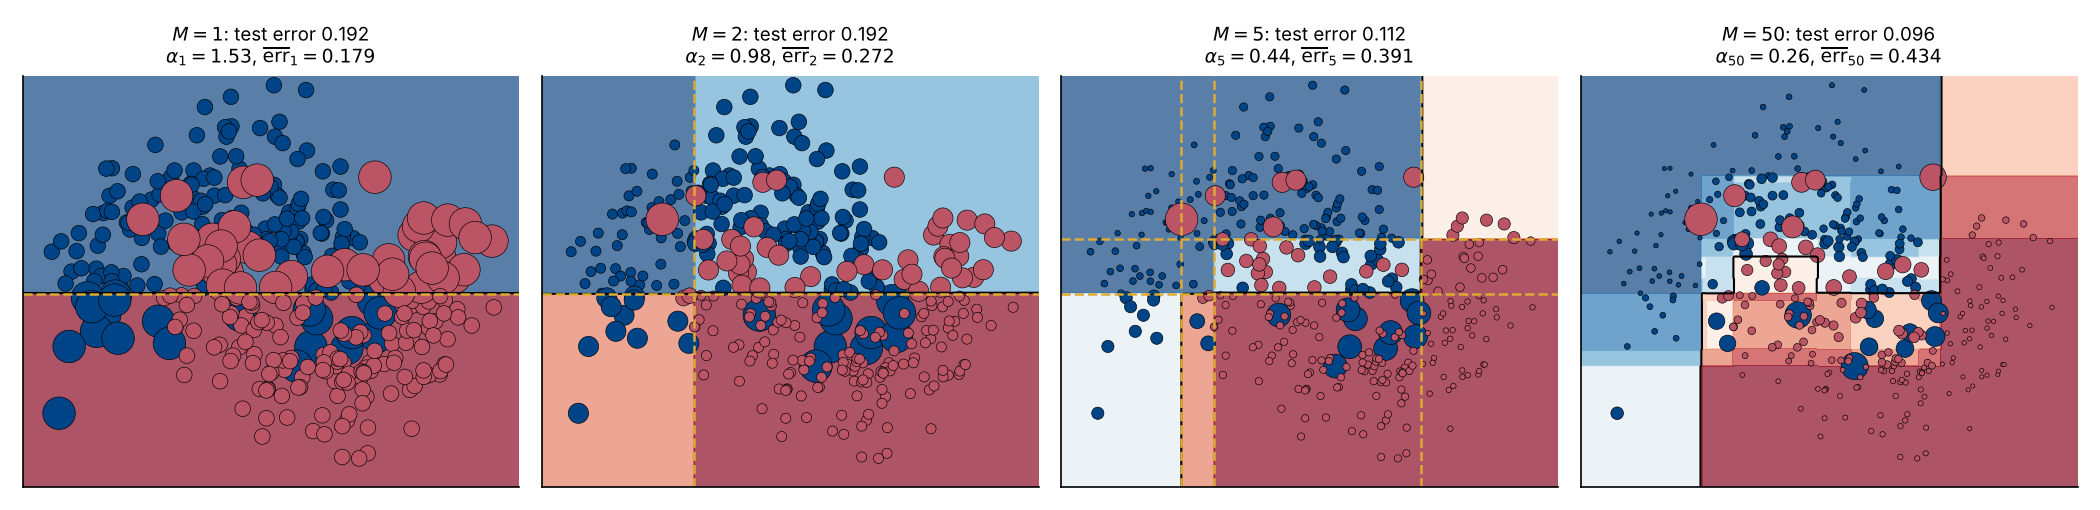

  margins at M=10: fraction <= 0: 0.096, median 0.396, min -0.544
  margins at M=200: fraction <= 0: 0.061, median 0.161, min -0.092


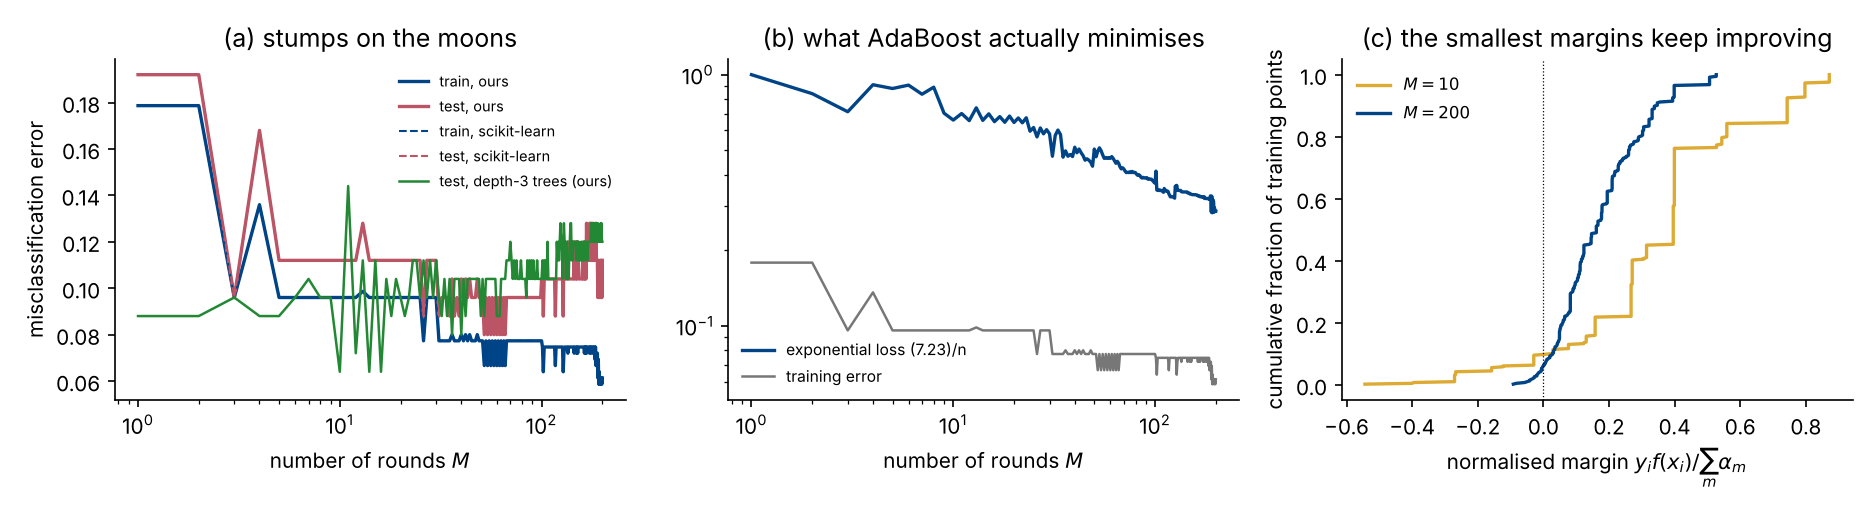

In [9]:
fig_adaboost_rounds(res_ada, data, "week47_adaboost_rounds.png")
display(Image("week47_adaboost_rounds.png"))
fig_adaboost_error(res_ada, "week47_adaboost_error.png")
display(Image("week47_adaboost_error.png"))

## Part 2 — Steepest descent in function space, and gradient boosting

### 2.1 The literal algorithm, Eq. (7.30)

Treat the $n$ predictions $f=(f(x_1),\dots,f(x_n))$ as the parameters and do
gradient descent on the training loss with an exact line search. For the
squared error $L=(y-f)^2$ the gradient is $g=-2(y-f)$; from $f_0=0$ the line
search gives $\rho_1=1/2$ and $f_1=y$: every training point is fitted exactly
after one step, the next gradient is zero — and $f_1$ is a list of $n$
numbers that says nothing about any other $x$. The regression problem of the
DocOnce notes: $y=e^{-x^2}+\tfrac32e^{-(x-2)^2}+\epsilon$, $x\in[-3,3]$,
$n=100$, $\epsilon\sim N(0,0.1^2)$.

In [10]:
def regression_data(n=100, noise=0.1, seed=SEED):
    """The regression problem of the DocOnce notes: two Gaussians on [-3, 3]."""
    rng = np.random.default_rng(seed)
    x = np.linspace(-3, 3, n)
    f = np.exp(-x**2) + 1.5 * np.exp(-(x - 2)**2)
    y = f + noise * rng.standard_normal(n)
    return x[:, None], y, f


def steepest_descent_in_function_space(y, steps=2):
    """Literal functional gradient descent for L = (y - f)^2 with an exact line
    search: f_0 = 0, g_1 = -2(y - f_0) = -2y, rho_1 = argmin sum (y + 2 rho y)^2
    = 1/2, so f_1 = f_0 - rho_1 g_1 = y -- the training points are fitted
    exactly after one step, and nothing exists between them."""
    f = np.zeros_like(y)
    rows = []
    for m in range(1, steps + 1):
        g = -2 * (y - f)
        # exact line search: minimise sum (y - f + rho g)^2 over rho
        rho = -np.dot(g, y - f) / np.dot(g, g) if np.dot(g, g) > 0 else 0.0
        f = f - rho * g
        rows.append((m, rho, np.mean((y - f)**2)))
    print("\nsteepest descent in function space (squared error, exact line search):")
    for m, rho, mse in rows:
        print(f"  step {m}: rho_{m} = {rho:.4f}, training MSE {mse:.2e}")
    return rows


### 2.2 Gradient boosting: the step along a tree

Fit a regression tree to the negative gradient (for the squared error: the
residual, Eq. 7.31), add it with a shrinkage factor $\nu$. Our own
implementation uses last week's regression tree; the library's trees use
Friedman's improved MSE criterion and break ties differently, so the two agree
on the method and differ in the third decimal of the test MSE. The figure:
(a) steepest descent fits the training points and nothing else; (b) staged
fits $f_1,f_5,f_{20},f_{100}$ with depth-2 trees; (c) the pseudo-residuals the
next tree is fitted to; (d) test MSE against $M$ for four learning rates —
$\nu M$ is roughly constant at the optimum, small $\nu$ reaches a lower
minimum and degrades more slowly, and every curve eventually rises: more
trees is not free.

In [11]:
class GradientBoostingRegressor:
    """Gradient boosting with the squared-error loss, Eq. (7.31) -- our own."""

    def __init__(self, n_estimators=100, learning_rate=0.1, max_depth=3, rng=None):
        self.n_estimators, self.lr, self.max_depth = n_estimators, learning_rate, max_depth
        self.rng = np.random.default_rng(0) if rng is None else rng

    def fit(self, X, y):
        X, y = np.asarray(X, dtype=float), np.asarray(y, dtype=float)
        self.f0_ = y.mean()                                   # the optimal constant
        f = np.full(len(y), self.f0_)
        self.trees_ = []
        for _ in range(self.n_estimators):
            residual = y - f                                  # the negative gradient
            tree = DecisionTree("regression", max_depth=self.max_depth, rng=self.rng).fit(X, residual)
            f = f + self.lr * tree.predict(X)                 # shrunken update
            self.trees_.append(tree)
        return self

    def predict(self, X, M=None):
        X = np.asarray(X, dtype=float)
        f = np.full(X.shape[0], self.f0_)
        for tree in self.trees_[:M]:
            f = f + self.lr * tree.predict(X)
        return f


def gb_regression(fname="week47_gb_regression.pdf"):
    from sklearn.model_selection import train_test_split
    from sklearn.ensemble import GradientBoostingRegressor as SkGBR
    X, y, ftrue = regression_data()
    Xtr, Xte, ytr, yte = train_test_split(X, y, test_size=0.2, random_state=SEED)
    xg = np.linspace(-3, 3, 600)[:, None]
    steepest_descent_in_function_space(ytr)

    fig, ax = plt.subplots(2, 2, figsize=(11, 6.6))
    ax = ax.ravel()
    # (a) steepest descent: the training points are fitted, nothing in between
    ax[0].plot(xg, np.exp(-xg**2) + 1.5 * np.exp(-(xg - 2)**2), color="k", lw=1, ls=":", label="true $f$")
    ax[0].scatter(Xtr, ytr, s=14, color=GREY, label="training data")
    ax[0].scatter(Xtr, ytr, s=40, facecolor="none", edgecolor=RED, lw=1.2, label="$f_1(x_i)=y_i$ after one line search")
    ax[0].scatter(Xte, yte, s=22, marker="x", color=BLUE, label="test points: $f_1$ undefined")
    ax[0].set_title("(a) steepest descent in function space: $\\rho_1=1/2$, training MSE 0")
    ax[0].legend(fontsize=7, frameon=False)

    # (b) gradient boosting with trees: staged fits
    sk = SkGBR(max_depth=2, learning_rate=0.1, n_estimators=300, random_state=SEED).fit(Xtr, ytr)
    staged = list(sk.staged_predict(xg))
    ax[1].scatter(Xtr, ytr, s=12, color=GREY)
    for m, col in zip([1, 5, 20, 100], [YELLOW, GREEN, BLUE, RED]):
        ax[1].plot(xg, staged[m - 1], color=col, lw=1.4, label=f"$f_{{{m}}}$")
    ax[1].plot(xg, np.exp(-xg**2) + 1.5 * np.exp(-(xg - 2)**2), color="k", lw=1, ls=":")
    ax[1].set_title("(b) gradient boosting, depth-2 trees, $\\nu=0.1$: $f_M$ for growing $M$")
    ax[1].legend(fontsize=8, frameon=False, ncol=4)

    # (c) residuals after M trees
    for m, col in zip([0, 5, 100], [GREY, GREEN, RED]):
        r = ytr - (np.full_like(ytr, ytr.mean()) if m == 0 else list(sk.staged_predict(Xtr))[m - 1])
        ax[2].scatter(Xtr, r, s=12, color=col, label=f"$M={m}$" + (" ($f_0=\\bar y$)" if m == 0 else ""))
    ax[2].axhline(0, color="k", lw=0.6)
    ax[2].set_title("(c) the pseudo-residuals $u_{im}=y_i-f_{m-1}(x_i)$ the next tree is fitted to")
    ax[2].legend(fontsize=8, frameon=False)

    # (d) test MSE against M for four learning rates
    table = {}
    for nu, col in zip([1.0, 0.3, 0.1, 0.03], [RED, YELLOW, BLUE, GREEN]):
        m = SkGBR(max_depth=2, learning_rate=nu, n_estimators=1000, random_state=SEED).fit(Xtr, ytr)
        te = np.array([np.mean((p - yte)**2) for p in m.staged_predict(Xte)])
        tr = np.array([np.mean((p - ytr)**2) for p in m.staged_predict(Xtr)])
        ax[3].plot(np.arange(1, 1001), te, color=col, lw=1.4, label=f"test, $\\nu={nu}$")
        ax[3].plot(np.arange(1, 1001), tr, color=col, lw=0.8, ls=":")
        table[nu] = (int(np.argmin(te)) + 1, te.min(), te[-1])
    ax[3].axhline(0.01, color="k", lw=0.6, ls="--", label="noise $\\sigma^2$")
    ax[3].set_xscale("log")
    ax[3].set_yscale("log")
    ax[3].set_ylim(2e-3, 1.5)
    ax[3].set_xlabel("number of trees $M$")
    ax[3].set_ylabel("MSE (solid test, dotted train)")
    ax[3].set_title("(d) $\\nu$ and $M$ trade off; too many trees overfit")
    ax[3].legend(fontsize=7, frameon=False, ncol=2)
    for a in ax[:3]:
        a.set_xlabel("$x$")
    fig.tight_layout()
    fig.savefig(fname)
    fig.savefig(fname.replace(".pdf", ".png"), dpi=150)
    plt.close(fig)

    # our own implementation against scikit-learn
    ours = GradientBoostingRegressor(100, 0.1, 2).fit(Xtr, ytr)
    sk100 = SkGBR(max_depth=2, learning_rate=0.1, n_estimators=100, random_state=SEED).fit(Xtr, ytr)
    print("\ngradient boosting regression (depth 2, nu=0.1, M=100): test MSE ours %.5f, sklearn %.5f" %
          (np.mean((ours.predict(Xte) - yte)**2), np.mean((sk100.predict(Xte) - yte)**2)))
    print("  learning-rate scan (best M, best test MSE, test MSE at M=1000):")
    for nu, (mbest, best, last) in table.items():
        print(f"    nu={nu:5.2f}: best M={mbest:4d}, MSE {best:.4f}, at 1000: {last:.4f}")
    return table



steepest descent in function space (squared error, exact line search):
  step 1: rho_1 = 0.5000, training MSE 0.00e+00
  step 2: rho_2 = 0.0000, training MSE 0.00e+00



gradient boosting regression (depth 2, nu=0.1, M=100): test MSE ours 0.01275, sklearn 0.01129
  learning-rate scan (best M, best test MSE, test MSE at M=1000):
    nu= 1.00: best M=   5, MSE 0.0127, at 1000: 0.0155
    nu= 0.30: best M=  13, MSE 0.0076, at 1000: 0.0155
    nu= 0.10: best M=  56, MSE 0.0084, at 1000: 0.0154
    nu= 0.03: best M= 137, MSE 0.0080, at 1000: 0.0140


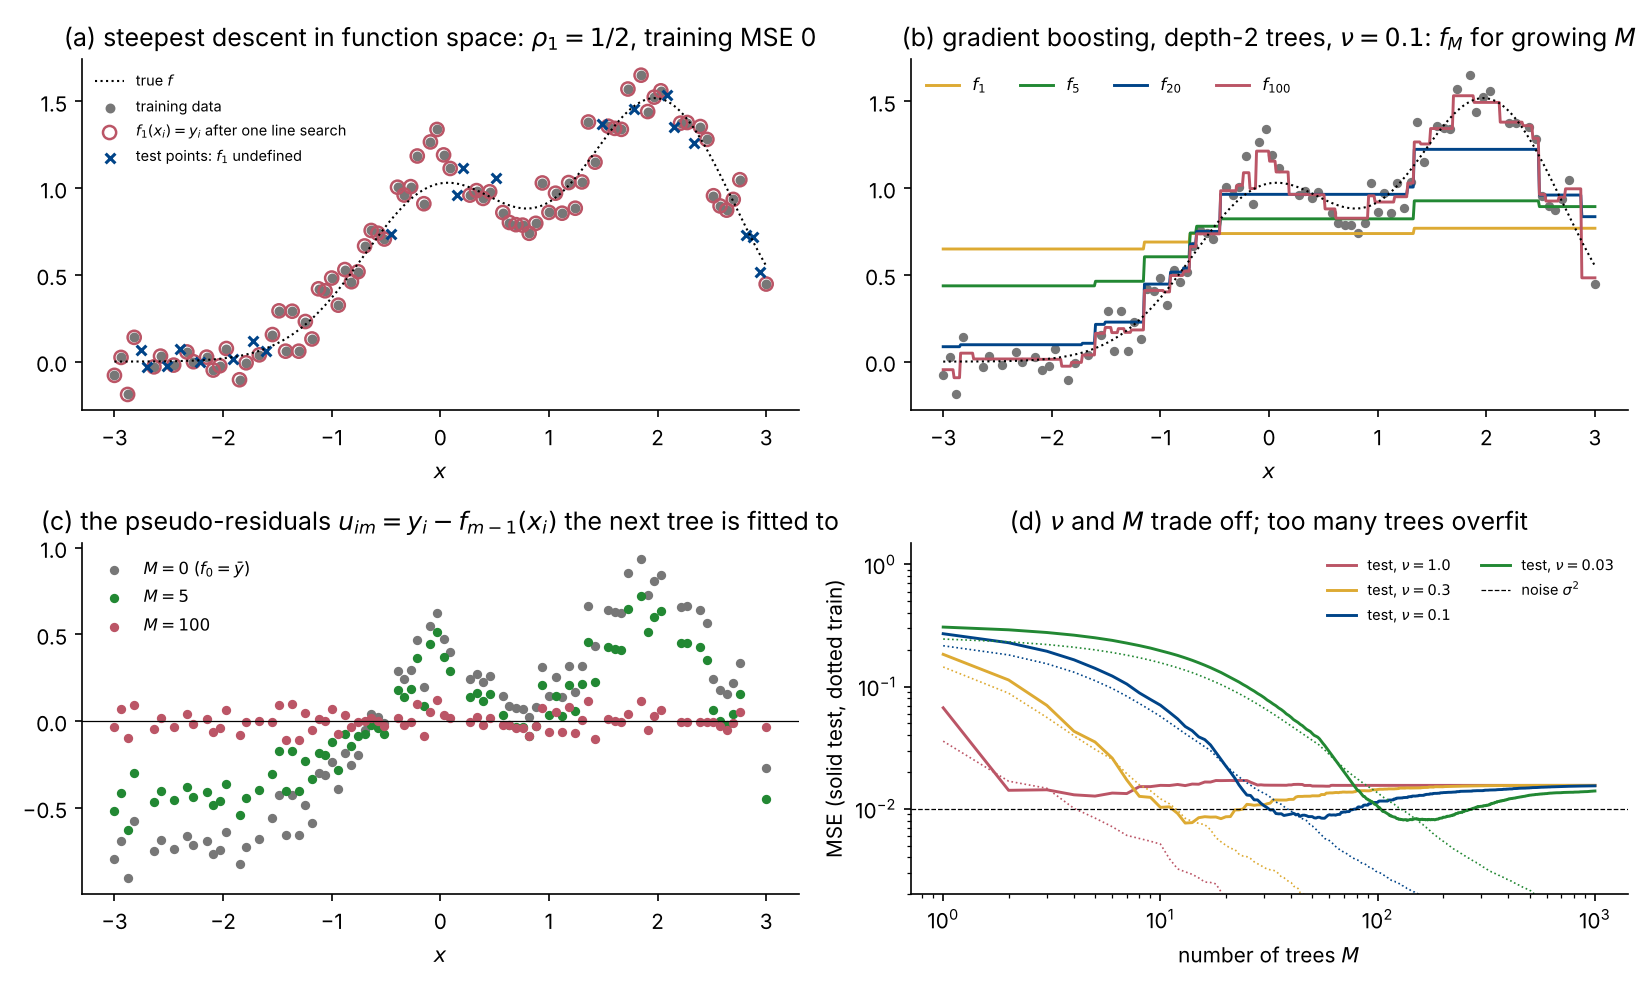

In [12]:
table_nu = gb_regression("week47_gb_regression.png")
display(Image("week47_gb_regression.png"))

### 2.3 Classification with the logistic loss, against AdaBoost

`GradientBoostingClassifier` fits trees to $u=y-p$, Eq. (7.32), and adds them
to the log-odds, so it outputs a probability $p=\sigma(f_M)$. On the moons it
reaches the Bayes error ($0.08$) at $M\approx25$ and then overfits like
AdaBoost — the cure for both is to stop early.

In [13]:
def gb_moons(res_ada, data, fname="week47_gb_moons.pdf"):
    """Gradient boosting with the logistic loss on the moons, against AdaBoost."""
    from sklearn.ensemble import GradientBoostingClassifier
    Xtr, Xte, ytr, yte = data
    gb = GradientBoostingClassifier(max_depth=2, learning_rate=0.1, n_estimators=300, random_state=SEED).fit(Xtr, ytr)
    te = np.array([np.mean(p != yte) for p in gb.staged_predict(Xte)])
    tr = np.array([np.mean(p != ytr) for p in gb.staged_predict(Xtr)])
    xx, yy = np.meshgrid(np.linspace(-1.8, 2.8, 250), np.linspace(-1.3, 1.8, 250))
    grid = np.c_[xx.ravel(), yy.ravel()]
    fig, ax = plt.subplots(1, 4, figsize=(14, 3.4))
    for a, m in zip(ax[:3], [1, 10, 300]):
        P = list(gb.staged_predict_proba(grid))[m - 1][:, 1].reshape(xx.shape)
        a.contourf(xx, yy, P, levels=np.linspace(0, 1, 11), cmap="RdBu_r", alpha=0.75)
        a.contour(xx, yy, P, levels=[0.5], colors="k", linewidths=1)
        a.scatter(Xte[yte == 0, 0], Xte[yte == 0, 1], s=10, color=BLUE, edgecolor="k", lw=0.3)
        a.scatter(Xte[yte == 1, 0], Xte[yte == 1, 1], s=10, color=RED, edgecolor="k", lw=0.3)
        a.set_title(f"$M={m}$: $p=\\sigma(f_M)$, test error {te[m-1]:.3f}", fontsize=9)
        a.set_xticks([])
        a.set_yticks([])
    ax[3].plot(np.arange(1, 301), te, color=RED, lw=1.5, label="gradient boosting, test")
    ax[3].plot(np.arange(1, 301), tr, color=RED, lw=0.8, ls=":", label="gradient boosting, train")
    r = res_ada[1]
    ax[3].plot(r["Ms"], r["our_te"], color=BLUE, lw=1.5, label="AdaBoost stumps, test")
    ax[3].plot(r["Ms"], r["our_tr"], color=BLUE, lw=0.8, ls=":", label="AdaBoost stumps, train")
    ax[3].set_xscale("log")
    ax[3].set_xlabel("$M$")
    ax[3].set_ylabel("misclassification error")
    ax[3].set_title("logistic loss vs exponential loss", fontsize=9)
    ax[3].legend(fontsize=7, frameon=False)
    fig.tight_layout()
    fig.savefig(fname)
    fig.savefig(fname.replace(".pdf", ".png"), dpi=150)
    plt.close(fig)
    print("\ngradient boosting classifier on the moons (depth 2, nu=0.1): test error at M=1/10/100/300: "
          + ", ".join(f"{te[m-1]:.3f}" for m in (1, 10, 100, 300)) + f"; best {te.min():.3f} at M={te.argmin()+1}")
    return te



gradient boosting classifier on the moons (depth 2, nu=0.1): test error at M=1/10/100/300: 0.088, 0.088, 0.128, 0.144; best 0.080 at M=25


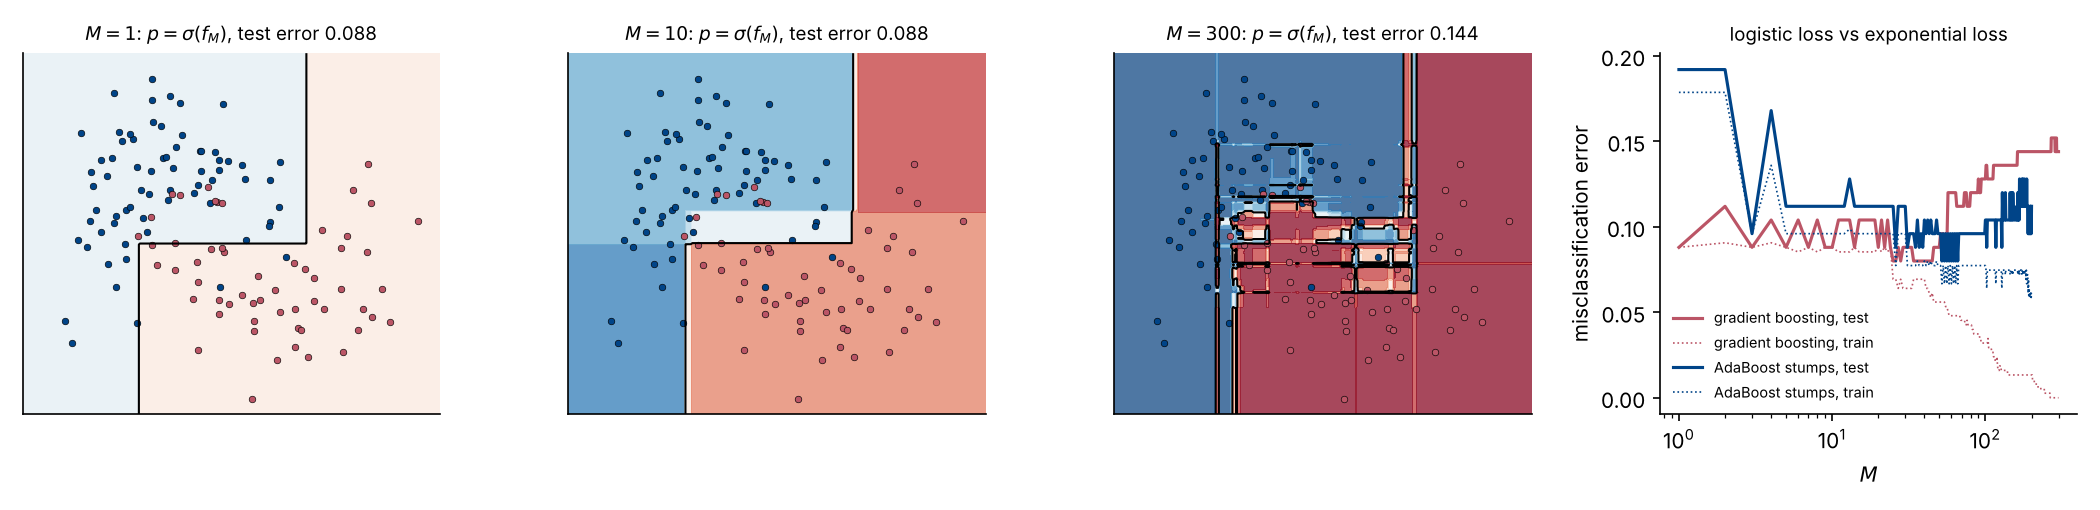

In [14]:
te_gb = gb_moons(res_ada, data, "week47_gb_moons.png")
display(Image("week47_gb_moons.png"))

## Part 3 — XGBoost

### 3.1 A leaf by hand, Eq. (7.36)

Second-order expansion of the loss, Eq. (7.33), with the penalty
$\Omega=\gamma J+\tfrac12\lambda\sum_jw_j^2$, Eq. (7.34). Per leaf,
$w_j^*=-G_j/(H_j+\lambda)$ with $G_j=\sum g_i$, $H_j=\sum h_i$. For the
logistic loss $g_i=p_i-y_i$ and $h_i=p_i(1-p_i)$. Three points with
$y=(1,0,1)$ and $p=0.6$: the unregularised Newton step is $0.278$, with
$\lambda=1$ it is $0.116$ — $\lambda$ bites when $H_j$ is small, that is, in
small or confident leaves.

In [15]:
def xgb_leaf_example(y=(1, 0, 1), p=(0.6, 0.6, 0.6), lam=1.0):
    """Eq. (7.36) on one leaf of three points, logistic loss: g_i = p_i - y_i,
    h_i = p_i(1 - p_i); w* = -G/(H + lambda)."""
    y, p = np.array(y, float), np.array(p, float)
    g, h = p - y, p * (1 - p)
    G, H = g.sum(), h.sum()
    w = -G / (H + lam)
    score = -0.5 * G**2 / (H + lam)
    print(f"\nXGBoost leaf example: g = {g}, h = {np.round(h, 3)}, G = {G:.2f}, H = {H:.3f}, "
          f"w* = {w:.4f} (lambda={lam}), unregularised w* = {-G/H:.4f}, score {score:.4f}")
    return G, H, w


In [16]:
G, H, w = xgb_leaf_example()


XGBoost leaf example: g = [-0.4  0.6 -0.4], h = [0.24 0.24 0.24], G = -0.20, H = 0.720, w* = 0.1163 (lambda=1.0), unregularised w* = 0.2778, score -0.0116


### 3.2 Regression with early stopping

`XGBRegressor` on the two-Gaussian problem, depth 2, $\nu=0.05$,
$\lambda=1$, stopping when the held-out loss has not improved for 50 rounds.
With only 20 test points the test MSE is noisy, so we also report the error
against the noise-free function on a grid, for XGBoost and for scikit-learn
with the same number of trees. (Stopping on the test set makes its error
optimistic — in a project, hold out a third set or cross-validate.)

In [17]:
def xgb_regression():
    """XGBRegressor on the two-Gaussian problem with early stopping on the
    held-out set, against scikit-learn with the same depth, learning rate and
    number of trees.  With only 20 test points the test MSE is noisy, so we
    also report the error against the noise-free function on a fine grid."""
    import xgboost as xgb
    from sklearn.model_selection import train_test_split
    from sklearn.ensemble import GradientBoostingRegressor as SkGBR
    X, y, ftrue = regression_data()
    Xtr, Xte, ytr, yte = train_test_split(X, y, test_size=0.2, random_state=SEED)
    xg = np.linspace(-3, 3, 600)[:, None]
    fg = np.exp(-xg[:, 0]**2) + 1.5 * np.exp(-(xg[:, 0] - 2)**2)
    reg = xgb.XGBRegressor(n_estimators=2000, learning_rate=0.05, max_depth=2, reg_lambda=1.0,
                           early_stopping_rounds=50, random_state=SEED)
    reg.fit(Xtr, ytr, eval_set=[(Xte, yte)], verbose=False)
    M = reg.best_iteration + 1
    sk = SkGBR(max_depth=2, learning_rate=0.05, n_estimators=M, random_state=SEED).fit(Xtr, ytr)
    out = dict(M=M,
               xgb_test=np.mean((reg.predict(Xte) - yte)**2), sk_test=np.mean((sk.predict(Xte) - yte)**2),
               xgb_grid=np.mean((reg.predict(xg) - fg)**2), sk_grid=np.mean((sk.predict(xg) - fg)**2))
    print(f"\nXGBRegressor (depth 2, nu=0.05, lambda=1, early stopping, patience 50): stopped at M={M}")
    print(f"  test MSE (20 points): XGBoost {out['xgb_test']:.4f}, scikit-learn with the same M {out['sk_test']:.4f}")
    print(f"  MSE against the true f on a grid: XGBoost {out['xgb_grid']:.4f}, scikit-learn {out['sk_grid']:.4f} "
          f"(noise variance 0.01)")
    return out


In [18]:
out_xgb = xgb_regression()


XGBRegressor (depth 2, nu=0.05, lambda=1, early stopping, patience 50): stopped at M=135
  test MSE (20 points): XGBoost 0.0200, scikit-learn with the same M 0.0090
  MSE against the true f on a grid: XGBoost 0.0054, scikit-learn 0.0045 (noise variance 0.01)


### 3.3 The Wisconsin breast-cancer data

Five models through one `predict_proba` interface: logistic regression on
scaled features, a random forest, scikit-learn's `GradientBoostingClassifier`
and `HistGradientBoostingClassifier`, and `XGBClassifier`; accuracy, AUC and
logloss on 171 held-out tumours. Then the logloss curves against the number of
rounds for three learning rates (the training loss never stops falling, the
test loss flattens after 50–150 rounds), the $\lambda$–$\gamma$ scan (with the
mean number of leaves per tree — $\gamma=5$ prunes every tree to a stump or a
single leaf), and the gain importances of Eq. (7.37). Logistic regression wins
on these data; the lesson is procedural — always report the simple baseline.

In [19]:
def xgb_cancer(fname="week47_xgb_cancer.pdf", B=200):
    import xgboost as xgb
    from sklearn.datasets import load_breast_cancer
    from sklearn.model_selection import train_test_split
    from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier, HistGradientBoostingClassifier
    from sklearn.linear_model import LogisticRegression
    from sklearn.preprocessing import StandardScaler
    from sklearn.pipeline import make_pipeline
    from sklearn.metrics import roc_auc_score, log_loss
    data = load_breast_cancer()
    X, y = data.data, data.target
    Xtr, Xte, ytr, yte = train_test_split(X, y, test_size=0.3, random_state=SEED, stratify=y)
    models = {
        "logistic regression (scaled)": make_pipeline(StandardScaler(), LogisticRegression(max_iter=5000)),
        "random forest, 200 trees": RandomForestClassifier(n_estimators=B, random_state=SEED),
        "gradient boosting (sklearn), depth 3": GradientBoostingClassifier(max_depth=3, learning_rate=0.1,
                                                                            n_estimators=B, random_state=SEED),
        "hist gradient boosting (sklearn)": HistGradientBoostingClassifier(max_depth=3, learning_rate=0.1,
                                                                            max_iter=B, random_state=SEED),
        "XGBoost, depth 3": xgb.XGBClassifier(n_estimators=B, learning_rate=0.1, max_depth=3, reg_lambda=1.0,
                                              gamma=0.0, random_state=SEED, eval_metric="logloss"),
    }
    res = {}
    print("\nWisconsin breast cancer, %d train / %d test:" % (len(ytr), len(yte)))
    for k, m in models.items():
        t0 = time.time()
        m.fit(Xtr, ytr)
        dt = time.time() - t0
        p = m.predict_proba(Xte)[:, 1]
        res[k] = (m.score(Xte, yte), roc_auc_score(yte, p), log_loss(yte, p), dt)
        print(f"  {k:38s} acc {res[k][0]:.4f}  AUC {res[k][1]:.4f}  logloss {res[k][2]:.4f}  ({dt:.2f} s)")

    # logloss curves for two learning rates, and the lambda/gamma scan
    fig, ax = plt.subplots(1, 2, figsize=(11, 3.8), gridspec_kw={"width_ratios": [1, 1.2]})
    for nu, col in zip([0.3, 0.1, 0.03], [RED, BLUE, GREEN]):
        m = xgb.XGBClassifier(n_estimators=600, learning_rate=nu, max_depth=3, reg_lambda=1.0,
                              random_state=SEED, eval_metric="logloss")
        m.fit(Xtr, ytr, eval_set=[(Xtr, ytr), (Xte, yte)], verbose=False)
        ev = m.evals_result()
        ax[0].plot(ev["validation_0"]["logloss"], color=col, lw=0.9, ls=":")
        ax[0].plot(ev["validation_1"]["logloss"], color=col, lw=1.5, label=f"$\\nu={nu}$")
    ax[0].set_yscale("log")
    ax[0].set_xlabel("boosting rounds")
    ax[0].set_ylabel("logloss (solid test, dotted train)")
    ax[0].set_title("(a) XGBoost on the cancer data: the training loss never stops", fontsize=9)
    ax[0].legend(fontsize=8, frameon=False)
    scan = {}
    for lam in (0.0, 1.0, 10.0):
        for gam in (0.0, 1.0, 5.0):
            m = xgb.XGBClassifier(n_estimators=B, learning_rate=0.1, max_depth=3, reg_lambda=lam, gamma=gam,
                                  random_state=SEED, eval_metric="logloss").fit(Xtr, ytr)
            scan[(lam, gam)] = (m.score(Xte, yte), log_loss(yte, m.predict_proba(Xte)[:, 1]),
                                int(sum(t.count("leaf") for t in m.get_booster().get_dump()) / B))
    print("  lambda/gamma scan (test acc, test logloss, mean leaves per tree):")
    for (lam, gam), (acc, ll, nl) in scan.items():
        print(f"    lambda={lam:4.1f} gamma={gam:3.1f}: acc {acc:.4f}, logloss {ll:.4f}, leaves/tree {nl}")
    imp = models["XGBoost, depth 3"].get_booster().get_score(importance_type="gain")
    names = {f"f{i}": n for i, n in enumerate(data.feature_names)}
    top = sorted(imp.items(), key=lambda kv: -kv[1])[:12]
    ax[1].barh(range(len(top))[::-1], [v for _, v in top], color=BLUE)
    ax[1].set_yticks(range(len(top))[::-1])
    ax[1].set_yticklabels([names[k] for k, _ in top], fontsize=8)
    ax[1].set_xlabel("mean gain, Eq. (7.37), over the splits on the feature")
    ax[1].set_title("(b) XGBoost gain importances", fontsize=9)
    fig.tight_layout()
    fig.savefig(fname)
    fig.savefig(fname.replace(".pdf", ".png"), dpi=150)
    plt.close(fig)
    return res, scan



Wisconsin breast cancer, 398 train / 171 test:
  logistic regression (scaled)           acc 0.9649  AUC 0.9924  logloss 0.0934  (0.01 s)


  random forest, 200 trees               acc 0.9532  AUC 0.9798  logloss 0.3318  (0.18 s)


  gradient boosting (sklearn), depth 3   acc 0.9532  AUC 0.9879  logloss 0.2378  (0.39 s)
  hist gradient boosting (sklearn)       acc 0.9591  AUC 0.9848  logloss 0.2286  (0.09 s)
  XGBoost, depth 3                       acc 0.9474  AUC 0.9855  logloss 0.1380  (0.05 s)


  lambda/gamma scan (test acc, test logloss, mean leaves per tree):
    lambda= 0.0 gamma=0.0: acc 0.9649, logloss 0.1415, leaves/tree 3
    lambda= 0.0 gamma=1.0: acc 0.9415, logloss 0.1484, leaves/tree 2
    lambda= 0.0 gamma=5.0: acc 0.9357, logloss 0.1629, leaves/tree 1
    lambda= 1.0 gamma=0.0: acc 0.9474, logloss 0.1380, leaves/tree 3
    lambda= 1.0 gamma=1.0: acc 0.9415, logloss 0.1458, leaves/tree 2
    lambda= 1.0 gamma=5.0: acc 0.9357, logloss 0.1619, leaves/tree 1
    lambda=10.0 gamma=0.0: acc 0.9474, logloss 0.1355, leaves/tree 5
    lambda=10.0 gamma=1.0: acc 0.9357, logloss 0.1457, leaves/tree 2
    lambda=10.0 gamma=5.0: acc 0.9298, logloss 0.1729, leaves/tree 1


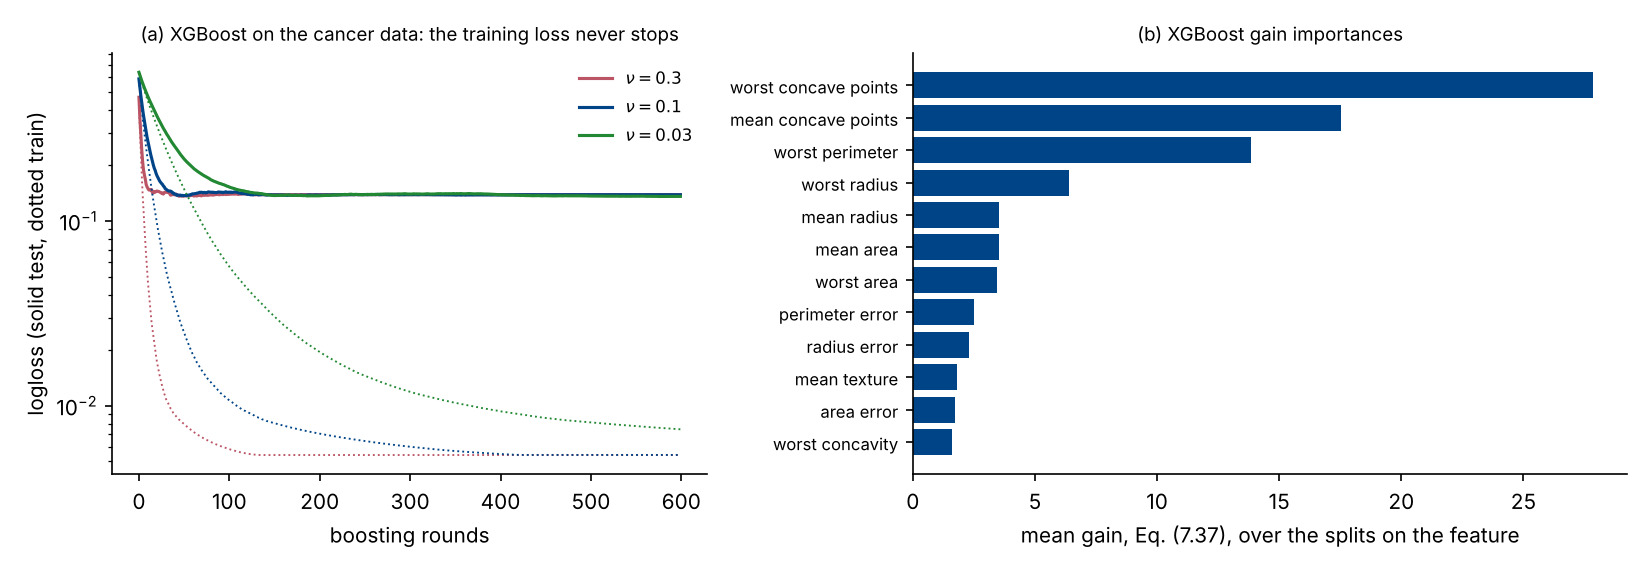

In [20]:
res_cancer, scan = xgb_cancer("week47_xgb_cancer.png")
display(Image("week47_xgb_cancer.png"))

## Summary

* Boosting is forward stagewise fitting of an additive model, Eq. (7.20): a
  sequence of weak learners, each fitted to what the previous ones got wrong.
  Averaging (bagging) reduces variance and cannot touch bias; boosting
  reduces bias stage by stage, and the depth of the weak learner sets the
  interaction order of the model.
* AdaBoost is the exponential loss (7.23) with stumps; the votes
  $\alpha_m$ and the weight update follow from (7.24)–(7.29), and the
  population minimiser is half the log-odds. Twenty lines of Python reproduce
  scikit-learn's `AdaBoostClassifier` to every digit. The exponential loss is
  fragile under label noise.
* Steepest descent in function space interpolates the training set in one
  step; restricting the step to a regression tree fitted to the negative
  gradient gives gradient boosting, with the residual (squared error) or
  $y-p$ (logistic loss) as the target. Shrinkage $\nu$ and the number of
  trees $M$ trade off; choose $M$ by validation.
* XGBoost expands the loss to second order and adds $\gamma J+\tfrac12\lambda\sum w_j^2$:
  leaf values $-G_j/(H_j+\lambda)$ and a split gain (7.37) in closed form for
  any twice-differentiable loss, grown on histograms in parallel.
* On the cancer data logistic regression beats all four ensembles: fit the
  simple baseline first, and show on held-out data that the complicated model
  earns its complexity.